# Consumer Complaint Classification

Predict the product category of a consumer complaint from its text.

Models compared:
- SimpleRNN, LSTM and GRU built from scratch (Keras)
- DistilBERT fine-tuned with HuggingFace Transformers

Dataset: [Consumer Complaints Dataset for NLP](https://www.kaggle.com/datasets/shashwatwork/consume-complaints-dataset-fo-nlp) (CFPB complaints, 5 categories).

## Setup

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # run Keras on PyTorch so it can use the GPU on Windows

import time, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras
from keras import layers
from keras.utils import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

from text_utils import clean_text, WordTokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
keras.utils.set_random_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("keras", keras.__version__, "| torch", torch.__version__)

os.makedirs("models", exist_ok=True)
os.makedirs("images", exist_ok=True)

device: cuda NVIDIA GeForce RTX 3060 Ti
keras 3.15.1 | torch 2.6.0+cu124


## 1. Load and explore the data

In [2]:
df = pd.read_csv("data/complaints_processed.csv")
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
print(df.shape)
df.head()

(162421, 2)


,product,narrative
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report speciali...
4,credit_reporting,payment history missing credit report made mis...


In [3]:
print(df.isna().sum())
print("duplicate rows:", df.duplicated().sum())

product       0
narrative    10
dtype: int64


duplicate rows: 37742


In [4]:
# drop empty and duplicated complaints
before = len(df)
df = df.dropna(subset=["narrative", "product"])
df = df[df["narrative"].str.strip() != ""]
df = df.drop_duplicates().reset_index(drop=True)
print(f"{before} -> {len(df)} rows")

162421 -> 124676 rows


In [5]:
df["n_words"] = df["narrative"].str.split().str.len()
df["n_words"].describe().round(1)

count    124676.0
mean         87.1
std         110.9
min           1.0
25%          30.0
50%          58.0
75%         104.0
max        2685.0
Name: n_words, dtype: float64

In [6]:
# one example per category
for cat, row in df.groupby("product").head(1).set_index("product").iterrows():
    print(f"[{cat}]\n{row['narrative'][:300]}...\n")

[credit_card]
purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order shipped several week stock since early due high demand although continuing take order guaranteeing r...

[retail_banking]
forwarded message cc sent friday pdt subject final legal payment well fargo well fargo clearly wrong need look actually opened account see court hearing several different government agency reporting well including branch put open account numerous fraudulent charge debit card connected account clearl...

[credit_reporting]
payment history missing credit report specialized loan servicing sl made mistake put account forbearance without authorization knowledge matter fact automatic payment setup month monthly mortgage paid full noticed issue account marked forbearance credit report tried get new home loan another new ban...

[mortgages_and_loans]
beginning mor

## 2. Text preprocessing

`clean_text` in `text_utils.py` lowercases the text, removes punctuation, numbers and special characters, removes stop words (plus the `xxxx` placeholders the CFPB uses to mask personal info) and lemmatizes each word.

The `narrative` column in this dataset is already partly cleaned by the dataset author, but running the same function here keeps training consistent with what the app does to new raw complaints.

In [7]:
sample = "I was charged $45.00 TWICE on 03/12/2023 for the same payments!! Account XXXX was closed."
print(clean_text(sample))

charged twice payment account closed


In [8]:
t0 = time.time()
df["clean"] = df["narrative"].apply(clean_text)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
print(f"done in {time.time() - t0:.0f}s, {len(df)} rows")
df[["narrative", "clean"]].head(3)

done in 8s, 124676 rows


,narrative,clean
0,purchase order day shipping amount receive pro...,purchase order day shipping amount receive pro...
1,forwarded message date tue subject please inve...,forwarded message date tue subject please inve...
2,forwarded message cc sent friday pdt subject f...,forwarded message cc sent friday pdt subject f...


## 3. Class distribution and imbalance

                     count  percent
product                            
credit_reporting     56303     45.2
debt_collection      21117     16.9
mortgages_and_loans  18759     15.0
credit_card          15024     12.1
retail_banking       13473     10.8
largest / smallest class: 4.2x


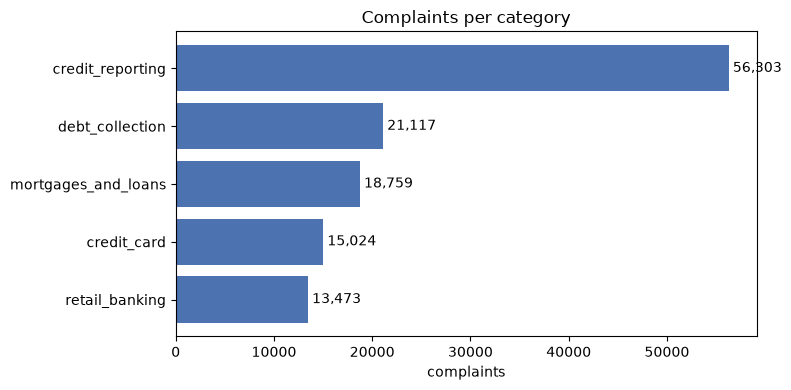

In [9]:
counts = df["product"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}))
print(f"largest / smallest class: {counts.max() / counts.min():.1f}x")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index[::-1], counts.values[::-1], color="#4C72B0")
for i, v in enumerate(counts.values[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlabel("complaints")
ax.set_title("Complaints per category")
plt.tight_layout()
plt.savefig("images/1_class_distribution.png", dpi=150)
plt.show()

In [10]:
CLASSES = sorted(df["product"].unique())
label2id = {c: i for i, c in enumerate(CLASSES)}
id2label = {i: c for c, i in label2id.items()}
df["label"] = df["product"].map(label2id)
NUM_CLASSES = len(CLASSES)

train_df, test_df = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.10, stratify=train_df["label"], random_state=SEED)
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")

train 89,766 | val 9,974 | test 24,936


credit_reporting is about 45% of the data, so I use balanced class weights during training to stop the models from leaning towards it.

In [11]:
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(weights)}
for i, w in CLASS_WEIGHTS.items():
    print(f"{id2label[i]:<22} {w:.3f}")

# keras fit() takes per-sample weights
train_sample_weight = train_df["label"].map(CLASS_WEIGHTS).values.astype("float32")

credit_card            1.660
credit_reporting       0.443
debt_collection        1.181
mortgages_and_loans    1.329
retail_banking         1.851


## 4. Tokenization and padding

In [12]:
VOCAB_SIZE = 20000
tokenizer = WordTokenizer(num_words=VOCAB_SIZE).fit_on_texts(train_df["clean"])
tokenizer.save("models/tokenizer.json")
print("vocab:", len(tokenizer.word_index) + 1)
print(list(tokenizer.word_index.items())[:10])

vocab: 20000
[('<OOV>', 1), ('account', 2), ('credit', 3), ('report', 4), ('payment', 5), ('information', 6), ('time', 7), ('would', 8), ('loan', 9), ('company', 10)]


In [13]:
lens = train_df["clean"].str.split().str.len()
print(lens.describe(percentiles=[.5, .75, .9, .95]).round(0))

MAX_LEN = 200
print(f"MAX_LEN={MAX_LEN} fully covers {(lens <= MAX_LEN).mean() * 100:.1f}% of complaints")

count    89766.0
mean        87.0
std        111.0
min          1.0
50%         58.0
75%        104.0
90%        179.0
95%        250.0
max       2680.0
Name: clean, dtype: float64
MAX_LEN=200 fully covers 92.1% of complaints


In [14]:
def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    # pre-padding so the RNN sees the real words last; long texts keep their first MAX_LEN words
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="pre", truncating="post")

X_train, X_val, X_test = to_padded(train_df["clean"]), to_padded(val_df["clean"]), to_padded(test_df["clean"])
y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values
print(X_train.shape, X_val.shape, X_test.shape)

(89766, 200) (9974, 200) (24936, 200)


## 5. SimpleRNN, LSTM and GRU

All three use the same architecture so the comparison is fair, only the recurrent layer changes:

Embedding(20000, 128) > RNN(64) > Dropout(0.3) > Dense(64, relu) > Dense(5, softmax)

In [15]:
EMBED_DIM, UNITS = 128, 64

def build_model(rnn_type):
    rnn_layer = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[rnn_type]
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM),
        rnn_layer(UNITS),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name=rnn_type)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_model("LSTM").summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,893 (9.97 MB)

 Trainable params: 2,613,893 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
EPOCHS, BATCH = 8, 128
results, test_preds = {}, {}

def evaluate(name, y_true, y_pred, train_time):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    f1w = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)[2]
    results[name] = {"accuracy": acc, "precision_macro": p, "recall_macro": r,
                     "f1_macro": f1, "f1_weighted": f1w, "train_time_min": train_time / 60}
    test_preds[name] = y_pred
    print(f"\n{name} (test set)")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3, zero_division=0))

def train_rnn(rnn_type):
    model = build_model(rnn_type)
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    t0 = time.time()
    model.fit(X_train, y_train, sample_weight=train_sample_weight,
              validation_data=(X_val, y_val),
              epochs=EPOCHS, batch_size=BATCH, callbacks=[early_stop], verbose=2)
    train_time = time.time() - t0
    y_pred = model.predict(X_test, batch_size=512, verbose=0).argmax(axis=1)
    evaluate(rnn_type, y_test, y_pred, train_time)
    model.save(f"models/{rnn_type}.keras")
    return model

In [17]:
rnn_model = train_rnn("SimpleRNN")

Epoch 1/8


702/702 - 68s - 97ms/step - accuracy: 0.4974 - loss: 1.1758 - val_accuracy: 0.5432 - val_loss: 1.0838


Epoch 2/8


702/702 - 65s - 92ms/step - accuracy: 0.5575 - loss: 1.1303 - val_accuracy: 0.5976 - val_loss: 1.0167


Epoch 3/8


702/702 - 65s - 93ms/step - accuracy: 0.6604 - loss: 0.8857 - val_accuracy: 0.7097 - val_loss: 0.7923


... (3 outputs left out)

702/702 - 66s - 93ms/step - accuracy: 0.7215 - loss: 0.7097 - val_accuracy: 0.6065 - val_loss: 0.9080


Epoch 6/8


702/702 - 65s - 93ms/step - accuracy: 0.6292 - loss: 0.9497 - val_accuracy: 0.6804 - val_loss: 0.8737



SimpleRNN (test set)
                     precision    recall  f1-score   support

        credit_card      0.618     0.580     0.598      3005
   credit_reporting      0.908     0.668     0.770     11261
    debt_collection      0.527     0.816     0.640      4223
mortgages_and_loans      0.751     0.768     0.759      3752
     retail_banking      0.661     0.848     0.743      2695

           accuracy                          0.717     24936
          macro avg      0.693     0.736     0.702     24936
       weighted avg      0.758     0.717     0.723     24936



In [18]:
lstm_model = train_rnn("LSTM")

Epoch 1/8


702/702 - 7s - 11ms/step - accuracy: 0.7491 - loss: 0.7205 - val_accuracy: 0.8120 - val_loss: 0.5785


Epoch 2/8


702/702 - 7s - 10ms/step - accuracy: 0.8228 - loss: 0.5256 - val_accuracy: 0.7921 - val_loss: 0.6227


Epoch 3/8


702/702 - 7s - 10ms/step - accuracy: 0.8318 - loss: 0.5035 - val_accuracy: 0.7831 - val_loss: 0.6701



LSTM (test set)
                     precision    recall  f1-score   support

        credit_card      0.686     0.843     0.757      3005
   credit_reporting      0.916     0.808     0.859     11261
    debt_collection      0.777     0.782     0.780      4223
mortgages_and_loans      0.755     0.867     0.807      3752
     retail_banking      0.837     0.858     0.847      2695

           accuracy                          0.822     24936
          macro avg      0.794     0.831     0.810     24936
       weighted avg      0.832     0.822     0.824     24936



In [19]:
gru_model = train_rnn("GRU")

Epoch 1/8


702/702 - 7s - 10ms/step - accuracy: 0.7167 - loss: 0.7349 - val_accuracy: 0.8044 - val_loss: 0.5716


Epoch 2/8


702/702 - 7s - 10ms/step - accuracy: 0.8350 - loss: 0.4421 - val_accuracy: 0.8182 - val_loss: 0.5267


Epoch 3/8


702/702 - 7s - 10ms/step - accuracy: 0.8541 - loss: 0.3797 - val_accuracy: 0.8232 - val_loss: 0.5112


Epoch 4/8


702/702 - 7s - 10ms/step - accuracy: 0.8700 - loss: 0.3286 - val_accuracy: 0.8180 - val_loss: 0.5330


Epoch 5/8


702/702 - 7s - 10ms/step - accuracy: 0.8822 - loss: 0.2919 - val_accuracy: 0.8224 - val_loss: 0.5360



GRU (test set)
                     precision    recall  f1-score   support

        credit_card      0.761     0.822     0.790      3005
   credit_reporting      0.929     0.807     0.864     11261
    debt_collection      0.736     0.826     0.778      4223
mortgages_and_loans      0.771     0.890     0.827      3752
     retail_banking      0.850     0.894     0.871      2695

           accuracy                          0.834     24936
          macro avg      0.809     0.848     0.826     24936
       weighted avg      0.844     0.834     0.836     24936



## 6. Fine-tuning DistilBERT

DistilBERT gets the `narrative` text directly (it has its own tokenizer, so no stop word removal). To keep training around 10 minutes on one GPU it's trained on a stratified 60k sample of the training set for 2 epochs, and it's tested on the same test set as the RNNs. The loss uses the same class weights.

In [20]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

MODEL_NAME = "distilbert-base-uncased"
TF_MAX_LEN = 256
TF_TRAIN_SIZE = 60000
TF_EPOCHS = 2
TF_BATCH = 16

hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tf_train = train_test_split(train_df, train_size=TF_TRAIN_SIZE, stratify=train_df["label"], random_state=SEED)[0]
tf_val = val_df.sample(5000, random_state=SEED)
print(len(tf_train), len(tf_val))

60000 5000


In [21]:
class ComplaintDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = hf_tokenizer(list(texts), truncation=True, max_length=TF_MAX_LEN)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item

train_ds = ComplaintDataset(tf_train["narrative"], tf_train["label"])
val_ds = ComplaintDataset(tf_val["narrative"], tf_val["label"])
test_ds = ComplaintDataset(test_df["narrative"], test_df["label"])

In [22]:
cw_tensor = torch.tensor([CLASS_WEIGHTS[i] for i in range(NUM_CLASSES)], dtype=torch.float)

class WeightedTrainer(Trainer):
    # same Trainer, but with class-weighted cross entropy
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=cw_tensor.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def hf_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)[2]}

tf_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id)

total_steps = int(np.ceil(len(train_ds) / TF_BATCH)) * TF_EPOCHS
args = TrainingArguments(
    output_dir="models/hf_checkpoints",
    num_train_epochs=TF_EPOCHS,
    per_device_train_batch_size=TF_BATCH,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=int(0.06 * total_steps),
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=200,
    fp16=(DEVICE == "cuda"),
    report_to="none",
    seed=SEED,
)
trainer = WeightedTrainer(model=tf_model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                          data_collator=DataCollatorWithPadding(hf_tokenizer), compute_metrics=hf_metrics)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

In [23]:
t0 = time.time()
trainer.train()
tf_train_time = time.time() - t0
print(f"training time: {tf_train_time / 60:.1f} min")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.432038,0.468965,0.816200,0.815487
2,0.379882,0.440863,0.849000,0.838707


training time: 13.0 min


In [24]:
y_pred_tf = trainer.predict(test_ds).predictions.argmax(-1)
evaluate("DistilBERT", y_test, y_pred_tf, tf_train_time)
trainer.save_model("models/DistilBERT")
hf_tokenizer.save_pretrained("models/DistilBERT")


DistilBERT (test set)
                     precision    recall  f1-score   support

        credit_card      0.751     0.849     0.797      3005
   credit_reporting      0.924     0.837     0.878     11261
    debt_collection      0.771     0.825     0.797      4223
mortgages_and_loans      0.815     0.866     0.840      3752
     retail_banking      0.868     0.909     0.888      2695

           accuracy                          0.849     24936
          macro avg      0.826     0.857     0.840     24936
       weighted avg      0.855     0.849     0.850     24936



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('models/DistilBERT\\tokenizer_config.json',
 'models/DistilBERT\\tokenizer.json')

## 7. Confusion matrices

Rows are the true category, columns the prediction, values normalized per row.

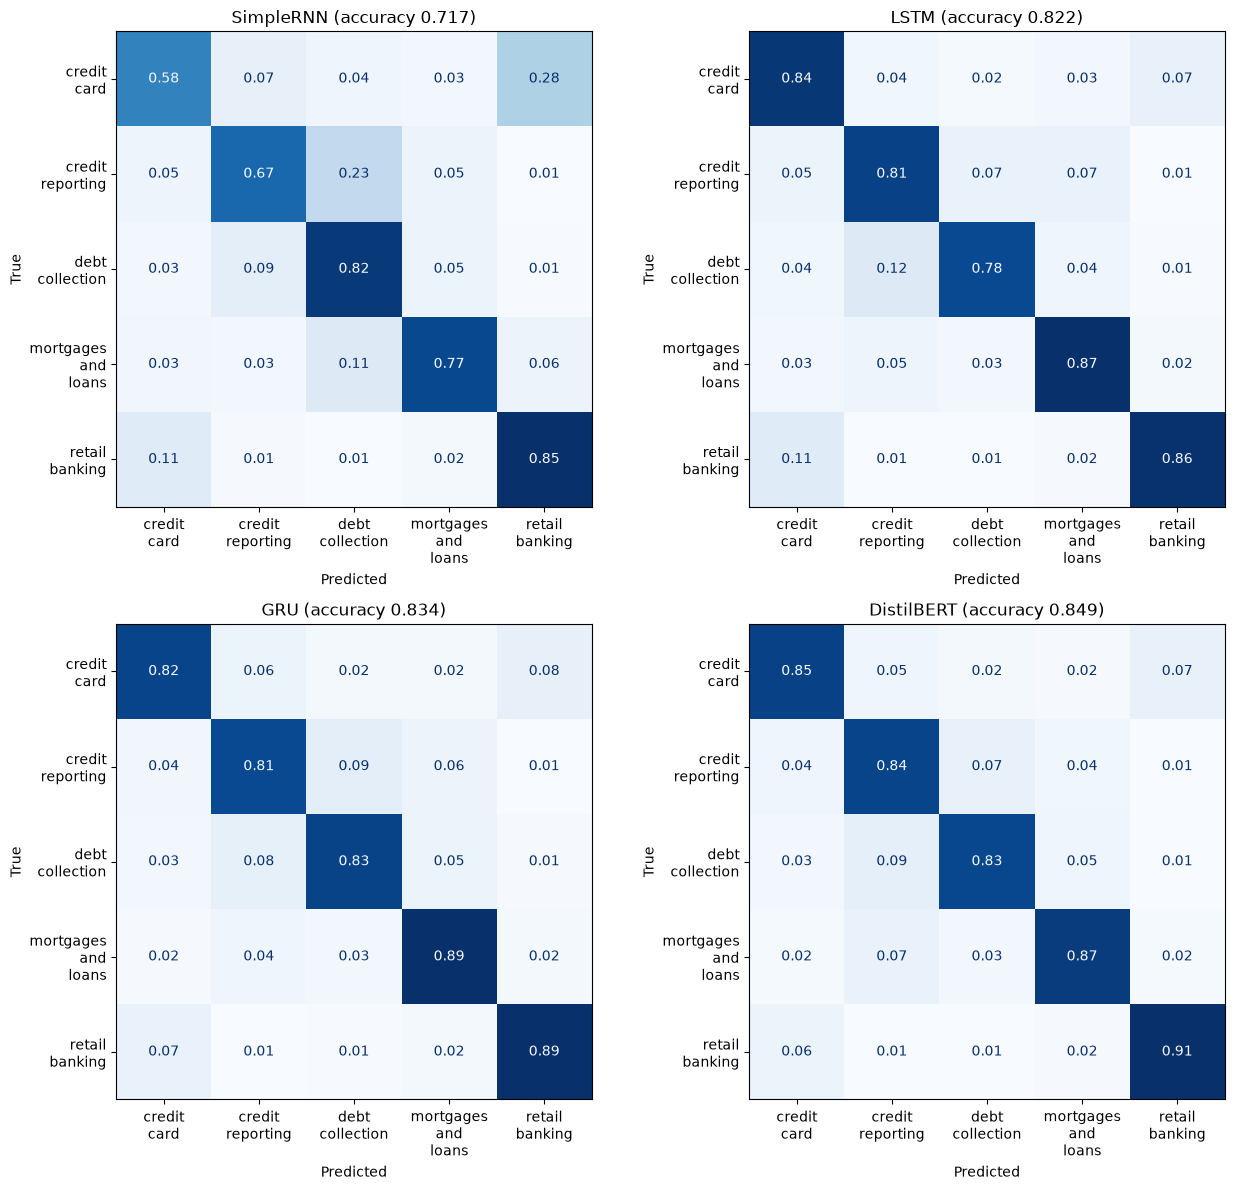

In [25]:
short = [c.replace("_", "\n") for c in CLASSES]
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for ax, name in zip(axes.ravel(), test_preds):
    cm = confusion_matrix(y_test, test_preds[name], normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=short).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{name} (accuracy {results[name]['accuracy']:.3f})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("images/3_confusion_matrices.png", dpi=150)
plt.show()

## 8. Model comparison

Ranked by macro F1 since the classes are imbalanced.

            accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  \
DistilBERT    0.8489           0.8258        0.8574    0.8401       0.8501   
GRU           0.8341           0.8095        0.8479    0.8261       0.8357   
LSTM          0.8219           0.7944        0.8315    0.8098       0.8239   
SimpleRNN     0.7169           0.6930        0.7360    0.7021       0.7227   

            train_time_min  
DistilBERT         12.9658  
GRU                 0.5773  
LSTM                0.3567  
SimpleRNN           6.5668  

best model: DistilBERT


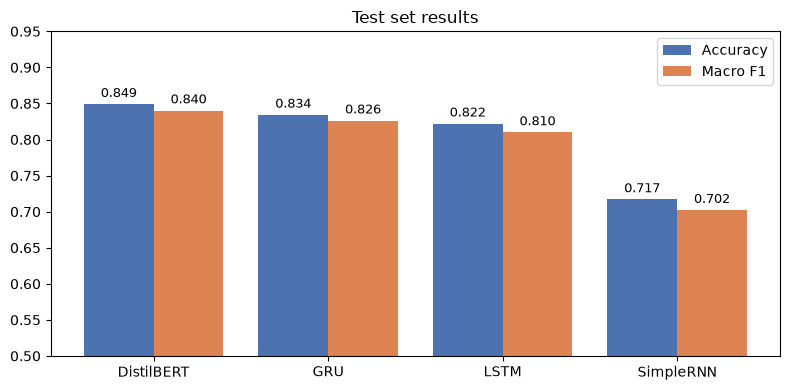

In [26]:
comparison = pd.DataFrame(results).T.sort_values("f1_macro", ascending=False).round(4)
print(comparison)
BEST = comparison.index[0]
print("\nbest model:", BEST)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(comparison))
ax.bar(x - 0.2, comparison["accuracy"], 0.4, label="Accuracy", color="#4C72B0")
ax.bar(x + 0.2, comparison["f1_macro"], 0.4, label="Macro F1", color="#DD8452")
for i, (a, f) in enumerate(zip(comparison["accuracy"], comparison["f1_macro"])):
    ax.text(i - 0.2, a + 0.01, f"{a:.3f}", ha="center", fontsize=9)
    ax.text(i + 0.2, f + 0.01, f"{f:.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(comparison.index)
ax.set_ylim(0.5, 0.95)
ax.set_title("Test set results")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("images/2_model_comparison.png", dpi=150)
plt.show()

with open("models/results.json", "w") as f:
    json.dump({"best_model": BEST, "classes": CLASSES, "max_len": MAX_LEN,
               "results": comparison.to_dict(orient="index")}, f, indent=2)

## 9. Classifying new complaints with the best model

In [27]:
keras_models = {"SimpleRNN": rnn_model, "LSTM": lstm_model, "GRU": gru_model}

def predict_complaint(text):
    if BEST == "DistilBERT":
        enc = hf_tokenizer(text, truncation=True, max_length=TF_MAX_LEN, return_tensors="pt").to(trainer.model.device)
        with torch.no_grad():
            probs = torch.softmax(trainer.model(**enc).logits, dim=-1)[0].cpu().numpy()
    else:
        probs = keras_models[BEST].predict(to_padded([clean_text(text)]), verbose=0)[0]
    i = int(probs.argmax())
    return id2label[i], float(probs[i])

new_complaints = [
    "There is an account on my credit report that is not mine and the bureau refuses to remove it.",
    "A collection agency keeps calling me at work about a debt I already paid off two years ago.",
    "My mortgage servicer added late fees even though my payment was on time, and now my loan modification was denied.",
    "I disputed a fraudulent charge on my credit card but the card company still charged me interest.",
    "The bank closed my checking account without notice and is holding my deposit.",
]
for c in new_complaints:
    label, conf = predict_complaint(c)
    print(f"[{label:<20} {conf:6.1%}]  {c}")

[credit_reporting      84.2%]  There is an account on my credit report that is not mine and the bureau refuses to remove it.
[debt_collection       97.9%]  A collection agency keeps calling me at work about a debt I already paid off two years ago.
[mortgages_and_loans   97.2%]  My mortgage servicer added late fees even though my payment was on time, and now my loan modification was denied.
[credit_card           95.8%]  I disputed a fraudulent charge on my credit card but the card company still charged me interest.
[retail_banking        98.0%]  The bank closed my checking account without notice and is holding my deposit.


## 10. Deployment

`app.py` loads the best model from `models/` and serves a Gradio interface: paste a complaint, get the predicted category and its confidence.

```
python app.py
```